In [ ]:
# Step 1: Define the Problem & Import Core Libraries
# Goal: Binary classification to predict survival (1 = Survived, 0 = Did not survive)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# Set visualization styles
sns.set_theme(style="whitegrid")
%matplotlib inline

In [ ]:
# Step 2.1: Load Datasets and inspect initial structure
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print(f"Train Shape: {train.shape}")
print(f"Test Shape: {test.shape}")
train.head()

Train Shape: (891, 12)
Test Shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# Step 2.2: Understand Data Types, Nulls, and Descriptive Statistics
print("--- Train Info ---")
train.info()

print("\n--- Missing Values in Train ---")
print(train.isnull().sum()[train.isnull().sum() > 0])

print("\n--- Numerical Summary ---")
train.describe()

--- Train Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

--- Missing Values in Train ---
Age         177
Cabin       687
Embarked      2
dtype: int64

--- Numerical Summary ---


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# Step 3: Data Cleaning

# 1. Impute missing Age with median based on Pclass and Sex
train["Age"] = train["Age"].fillna(
    train.groupby(["Pclass", "Sex"])["Age"].transform("median")
)
test["Age"] = test["Age"].fillna(
    test.groupby(["Pclass", "Sex"])["Age"].transform("median")
)

# 2. Impute missing Embarked with the mode
train["Embarked"] = train["Embarked"].fillna(train["Embarked"].mode()[0])

# 3. Impute missing Fare in test set with median
test["Fare"] = test["Fare"].fillna(test["Fare"].median())

# 4. Drop Cabin (too many nulls) and unneeded identifier columns
train.drop(columns=["Cabin", "PassengerId", "Ticket"], inplace=True)
test.drop(columns=["Cabin", "Ticket"], inplace=True)

print("Remaining null values in Train:")
print(train.isnull().sum())

Remaining null values in Train:
Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


/tmp/ipykernel_1549/3390901920.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], x="Survived", data=train, palette="Set2")
/tmp/ipykernel_1549/3390901920.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x="Sex", y="Survived", data=train, palette="muted")
/tmp/ipykernel_1549/3390901920.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[2], x="Pclass", y="Survived", data=train, palette="Blues_d")


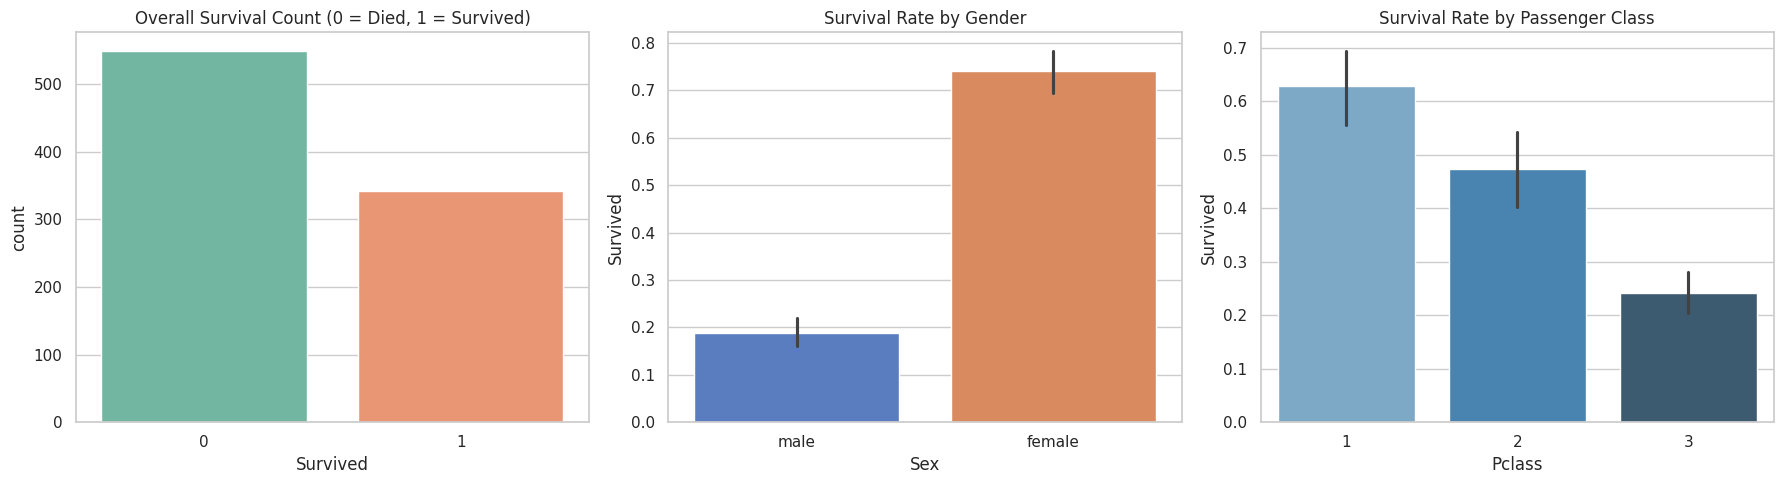

In [ ]:
# Step 4.1: Exploratory Data Analysis - Categorical Relationships
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Survival counts
sns.countplot(ax=axes[0], x="Survived", data=train, palette="Set2")
axes[0].set_title("Overall Survival Count (0 = Died, 1 = Survived)")

# Survival by Sex
sns.barplot(ax=axes[1], x="Sex", y="Survived", data=train, palette="muted")
axes[1].set_title("Survival Rate by Gender")

# Survival by Pclass
sns.barplot(ax=axes[2], x="Pclass", y="Survived", data=train, palette="Blues_d")
axes[2].set_title("Survival Rate by Passenger Class")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1549/305301040.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], x="Survived", y="Fare", data=train, palette="Pastel1")


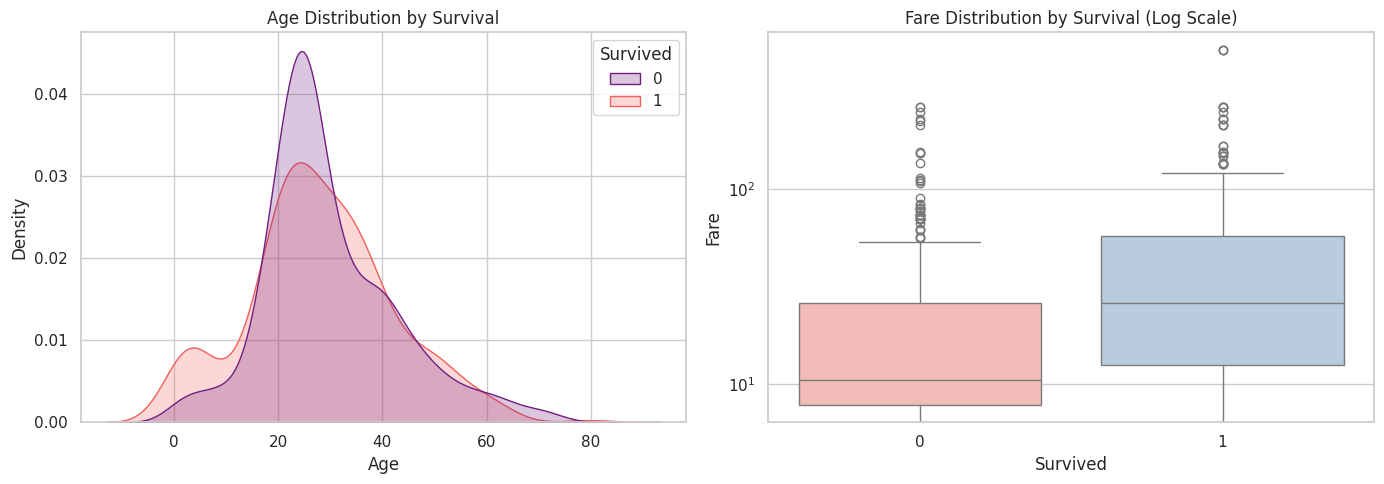

In [ ]:
# Step 4.2: Exploratory Data Analysis - Numerical Feature Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution by survival
sns.kdeplot(
    ax=axes[0],
    data=train,
    x="Age",
    hue="Survived",
    fill=True,
    common_norm=False,
    palette="magma",
)
axes[0].set_title("Age Distribution by Survival")

# Fare distribution by survival (log scale due to skewness)
sns.boxplot(ax=axes[1], x="Survived", y="Fare", data=train, palette="Pastel1")
axes[1].set_yscale("log")
axes[1].set_title("Fare Distribution by Survival (Log Scale)")

plt.tight_layout()
plt.show()

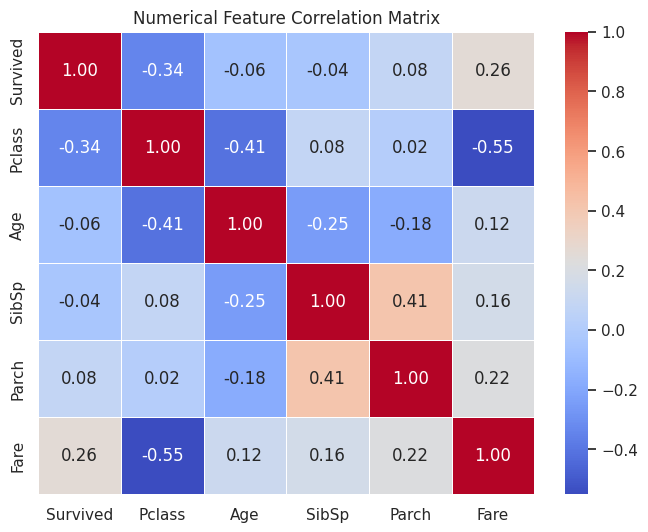

In [ ]:
# Step 4.3: Correlation Analysis
plt.figure(figsize=(8, 6))

numeric_train = train.select_dtypes(include=[np.number])
corr_matrix = numeric_train.corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Numerical Feature Correlation Matrix")
plt.show()